# SDS Mini Datathon 2026: Submission Notebook

**Team name:** [Your team name]

**Members:** [Name 1], [Name 2], [Name 3]

---

### Before you start
- Keep every section heading below, in this order. You may add cells and sub-headings inside each section.
- This notebook must run on **Python 3.14** using **Restart & Run All**, with no errors, in under **10 minutes**.
- Every chart in your deck must be generated in this notebook.
- Load data from the `data/` folder using relative paths only. Do not load data live from a website or API.
- Delete these instruction cells (the ones starting with *Instructions*) before submitting if you like, but keep the headings.

### Before you submit
1. Kernel → **Restart & Run All**, and check there are no errors.
2. Save the notebook with all outputs.
3. Export it as `main.html` (File → Save and Export Notebook As → HTML).
4. Zip the `TeamName/` folder: `main.ipynb`, `main.html`, `requirements.txt`, `deck.pdf`, `data/`.

## 1. Setup & Imports

*Instructions:* Import every library you use here. Each one must be listed, with its exact version, in `requirements.txt`.

In [1]:
import sys
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

In [2]:
# Python version check: the judges' environment uses Python 3.14
print(f"Python version: {sys.version.split()[0]}")
if sys.version_info[:2] != (3, 14):
    print("WARNING: this notebook will be run on Python 3.14. Please test it on 3.14 before submitting.")

Python version: 3.14.6


In [3]:
# Random seed: keep this so your results are reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
# If you use other libraries with randomness, set their seeds too,
# e.g. random_state=SEED in scikit-learn models

In [4]:
# Display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Chart style: light solid gridlines, no top/right border, left-aligned titles
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 20,  # leaves room for the policy-change labels drawn above timelines
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 1.8,
    "legend.frameon": False,
    "legend.fontsize": 9,
})

# One colour per thing, used the same way in every chart
COLOR_A = "#2a78d6"       # Category A (blue)
COLOR_B = "#eb6834"       # Category B (orange)
COLOR_E = "#1baf7a"       # Category E (aqua)
COLOR_EV = "#008300"      # fully electric cars (green)
COLOR_HYBRID = "#7ac27a"  # hybrid cars (light green)
INK = "#0b0b0b"           # a chart's main single series
GREY = "#898781"          # context series and labels
LIGHT_GREY = "#c3c2b7"    # background series

# Show premiums as S$ with thousands, e.g. 120000 -> "S$120k"
SGD_THOUSANDS = mticker.FuncFormatter(lambda value, _: f"S${value / 1000:,.0f}k")
PERCENT = mticker.FuncFormatter(lambda value, _: f"{value:.0f}%")

## 2. Data Ingestion

*Instructions:* Load all data from the `data/` folder using relative paths. If you use any additional public datasets, download them into `data/` and cite them in Section 9.

In [5]:
# Provided datasets (file names match the files in data/)
coe = pd.read_csv("data/coe_bidding.csv")
registrations = pd.read_csv("data/NewRegistrationofCarsbyMake.csv")

print(f"COE bidding data: {coe.shape[0]:,} rows, {coe.shape[1]} columns")
print(f"Registration data: {registrations.shape[0]:,} rows, {registrations.shape[1]} columns")

COE bidding data: 1,990 rows, 7 columns
Registration data: 51,669 rows, 6 columns


In [6]:
coe.head()

,month,bidding_no,vehicle_class,quota,bids_success,bids_received,premium
0,2010-01,1,Category A,1152,1145,1342,18502
1,2010-01,1,Category B,687,679,883,19190
2,2010-01,1,Category C,173,173,265,19001
3,2010-01,1,Category D,373,365,509,889
4,2010-01,1,Category E,586,567,1011,19889


In [7]:
registrations.head()

,month,make,importer_type,fuel_type,vehicle_type,number
0,2016-01,ALFA ROMEO,NaN,Petrol,Hatchback,3.0
1,2016-01,ALPINA,NaN,Petrol,Hatchback,0.0
2,2016-01,ASTON MARTIN,NaN,Petrol,Hatchback,0.0
3,2016-01,AUDI,NaN,Petrol,Hatchback,45.0
4,2016-01,B.M.W.,NaN,Petrol,Hatchback,5.0


## 3. Data Cleaning

*Instructions:* Show every cleaning step, with a short note on why. For example: fixing data types, handling missing values, removing duplicates, and aggregating registrations to monthly totals before joining with the COE data.

**Reminder:** the two datasets overlap from January 2016 to May 2025.

**Our rule for cleaning:** we only change a value when the data itself shows it is wrong, and every changed value is flagged in its own column so it stays visible. We clean each dataset on its own first (3.1 and 3.2), then join them (3.3).

### 3.1 COE bidding data

**Step 1: Check data types and missing values.** Before changing anything, look at what pandas read in.

In [8]:
print(coe.dtypes)
print()
print("Missing values in each column:")
print(coe.isna().sum())

month              str
bidding_no       int64
vehicle_class      str
quota            int64
bids_success       str
bids_received      str
premium          int64
dtype: object

Missing values in each column:
month            0
bidding_no       0
vehicle_class    0
quota            0
bids_success     0
bids_received    0
premium          0
dtype: int64


**What we found:** there are no missing values, but `bids_success` and `bids_received` were read as **text**, not numbers. Some values are written with a thousands comma (e.g. `"1,007"`), so pandas could not read them as numbers.

**Step 2: Turn the number columns into real numbers.** Remove the commas, then convert.

In [9]:
number_cols = ["quota", "bids_success", "bids_received", "premium"]

for col in number_cols:
    # Make sure the column is text, then count and remove commas: "1,007" -> "1007"
    as_text = coe[col].astype(str)
    print(f"{col}: {as_text.str.contains(',').sum()} values written with a comma")
    # Convert the cleaned text into numbers
    coe[col] = pd.to_numeric(as_text.str.replace(",", ""))

print()
print(coe[number_cols].dtypes)

quota: 0 values written with a comma
bids_success: 41 values written with a comma
bids_received: 109 values written with a comma
premium: 0 values written with a comma

quota            int64
bids_success     int64
bids_received    int64
premium          int64
dtype: object


**Step 3: Turn `month` into a real date.** Right now it is text like `"2010-01"`. As a date, pandas can sort it, filter it and plot it on a time axis.

In [10]:
coe["month"] = pd.to_datetime(coe["month"], format="%Y-%m")
print("From", coe["month"].min().date(), "to", coe["month"].max().date())

From 2010-01-01 to 2026-10-01


**Step 4: Check for duplicates and that every month is complete.** Each month + bidding round + vehicle class should appear exactly once, so every month should have 10 rows (2 rounds × 5 categories).

In [11]:
duplicates = coe.duplicated(subset=["month", "bidding_no", "vehicle_class"]).sum()
print("Duplicate rows:", duplicates)

rows_per_month = coe.groupby("month").size()
print("Months by number of rows:", rows_per_month.value_counts().to_dict())
print("Bidding round numbers:", sorted(coe["bidding_no"].unique().tolist()))
print("Vehicle classes:", sorted(coe["vehicle_class"].unique()))

Duplicate rows: 0
Months by number of rows: {10: 199}
Bidding round numbers: [1, 2]
Vehicle classes: ['Category A', 'Category B', 'Category C', 'Category D', 'Category E']


**Step 5: Check for missing months.** Every month from Jan 2010 to Oct 2026 should have results.

In [12]:
all_months = pd.date_range(coe["month"].min(), coe["month"].max(), freq="MS")  # "MS" = first day of each month
months_in_data = pd.DatetimeIndex(coe["month"].unique())
missing_months = all_months.difference(months_in_data)

print("Months with no bidding results:", list(missing_months.strftime("%Y-%m")))

Months with no bidding results: ['2020-04', '2020-05', '2020-06']


**What we found:** April to June 2020 are missing. COE bidding was suspended during the COVID-19 circuit breaker, so these rounds never happened. We **do not fill them in** with made-up values. We keep the gap and mark it on our charts.

**Step 6: Check that the numbers agree with each other.** In any bidding round:
- successful bids cannot be more than the quota, or more than the bids received;
- premiums must be above zero;
- if fewer bids come in than there are COEs (an *undersubscribed* round), every bid should succeed.

In [13]:
checks = {
    "successful bids > quota": coe["bids_success"] > coe["quota"],
    "successful bids > bids received": coe["bids_success"] > coe["bids_received"],
    "premium <= 0": coe["premium"] <= 0,
    "bids received < quota (undersubscribed)": coe["bids_received"] < coe["quota"],
}
for name, failed in checks.items():
    print(f"{name}: {failed.sum()} rows")

coe[checks["bids received < quota (undersubscribed)"]]

successful bids > quota: 0 rows
successful bids > bids received: 0 rows
premium <= 0: 0 rows
bids received < quota (undersubscribed): 1 rows


,month,bidding_no,vehicle_class,quota,bids_success,bids_received,premium
11,2010-02-01,1,Category B,1154,690,930,23180


**What we found:** only **one** of 1,990 rows is undersubscribed: **Feb 2010, round 1, Category B**. The row contradicts itself: 930 bids came in for 1,154 COEs, so all 930 should have won, but only 690 did. Its quota of 1,154 is also exactly the Cat A quota in that same round. Compare it with the rounds around it:

In [14]:
early_ab = coe[coe["vehicle_class"].isin(["Category A", "Category B"]) & (coe["month"] <= "2010-03-01")]
early_ab.sort_values(["vehicle_class", "month", "bidding_no"])[
    ["month", "bidding_no", "vehicle_class", "quota", "bids_success", "bids_received", "premium"]]

,month,bidding_no,vehicle_class,quota,bids_success,bids_received,premium
0,2010-01-01,1,Category A,1152,1145,1342,18502
5,2010-01-01,2,Category A,1151,1149,1673,20501
10,2010-02-01,1,Category A,1154,1153,1326,19989
15,2010-02-01,2,Category A,1148,1148,1493,20340
20,2010-03-01,1,Category A,1148,1141,1758,20802
25,2010-03-01,2,Category A,1146,1137,2183,28389
1,2010-01-01,1,Category B,687,679,883,19190
6,2010-01-01,2,Category B,717,717,1105,22400
11,2010-02-01,1,Category B,1154,690,930,23180
16,2010-02-01,2,Category B,685,658,956,23889


Every other Cat B quota nearby is about 690, not 1,154. How close is the quota to the number of successful bids in a normal round?

In [15]:
normal_rounds = coe[coe["bids_received"] >= coe["quota"]]
unused_coes = normal_rounds["quota"] - normal_rounds["bids_success"]

print(f"In the other {len(normal_rounds):,} rounds, quota minus successful bids is:")
print(f"  median {unused_coes.median():.0f}, 95th percentile {unused_coes.quantile(0.95):.0f}")

In the other 1,989 rounds, quota minus successful bids is:
  median 4, 95th percentile 35


In a normal round, the quota is only a few COEs above the number of successful bids. So the quota for this round was almost certainly about 690, and 1,154 looks like Cat A's figure copied into the Cat B row. We **replace the quota with the number of successful bids (690)** and flag the row.

Effect of this fix: the premium is not changed. It only changes this round's bids-to-quota ratio (from 0.81 to 1.35), and Feb 2010 is outside the Jan 2016 to May 2025 window we use for joining.

In [16]:
bad_quota = (
    (coe["month"] == "2010-02-01") & (coe["bidding_no"] == 1) & (coe["vehicle_class"] == "Category B")
)
coe["quota_corrected"] = bad_quota  # True only for the corrected row
coe.loc[bad_quota, "quota"] = coe.loc[bad_quota, "bids_success"]

coe.loc[bad_quota, ["month", "bidding_no", "vehicle_class", "quota", "bids_success", "bids_received", "quota_corrected"]]

,month,bidding_no,vehicle_class,quota,bids_success,bids_received,quota_corrected
11,2010-02-01,1,Category B,690,690,930,True


**Step 7: Look for premiums that are far from their neighbours.** We compare each premium with the median of the 7 nearest rounds in the same category. Anything below half or above double that median gets a closer look.

In [17]:
coe = coe.sort_values(["vehicle_class", "month", "bidding_no"]).reset_index(drop=True)

neighbour_median = coe.groupby("vehicle_class")["premium"].transform(
    lambda s: s.rolling(window=7, center=True, min_periods=3).median()
)
coe["premium_vs_neighbours"] = coe["premium"] / neighbour_median

suspicious = coe[(coe["premium_vs_neighbours"] > 2) | (coe["premium_vs_neighbours"] < 0.5)]
suspicious[["month", "bidding_no", "vehicle_class", "quota", "bids_received", "premium", "premium_vs_neighbours"]]

,month,bidding_no,vehicle_class,quota,bids_received,premium,premium_vs_neighbours
1195,2010-01-01,2,Category D,378,551,20090,20.069930
1508,2023-05-01,1,Category D,554,670,5002,0.454686


**What we found:** two Category D (motorcycle) premiums stand out.
- **Jan 2010, round 2: S$20,090**, which is 20 times its neighbours (about S$1,000). The table below shows it is exactly the same as the **Category C** premium in that round, so it looks like a copied value.
- **May 2023, round 1: S$5,002**, about half its neighbours. Nothing else in the row disagrees, and bids then more than doubled in the next round (bids-to-quota 2.5), which is what we would expect after a real price dip. We **keep** this one.

In [18]:
jan_2010_round_2 = coe[(coe["month"] == "2010-01-01") & (coe["bidding_no"] == 2)]
jan_2010_round_2[["month", "bidding_no", "vehicle_class", "quota", "bids_received", "premium"]]

,month,bidding_no,vehicle_class,quota,bids_received,premium
1,2010-01-01,2,Category A,1151,1673,20501
399,2010-01-01,2,Category B,717,1105,22400
797,2010-01-01,2,Category C,181,280,20090
1195,2010-01-01,2,Category D,378,551,20090
1593,2010-01-01,2,Category E,588,1322,21899


We **remove** the Jan 2010 Cat D premium (set it to missing) instead of guessing a value, and flag it. Category D is not used in our Cat A vs Cat B analysis, so this has no effect on our results. It just keeps the cleaned table honest.

In [19]:
bad_premium = (
    (coe["month"] == "2010-01-01") & (coe["bidding_no"] == 2) & (coe["vehicle_class"] == "Category D")
)
coe["premium_removed"] = bad_premium
coe.loc[bad_premium, "premium"] = np.nan

# Put the rows back in time order and drop the helper column
coe = coe.drop(columns="premium_vs_neighbours")
coe = coe.sort_values(["month", "bidding_no", "vehicle_class"]).reset_index(drop=True)

print("Rows changed: quota", coe["quota_corrected"].sum(), "| premium", coe["premium_removed"].sum())

Rows changed: quota 1 | premium 1


**Step 8: Give each bidding round its own date.** There are 2 rounds per month. To plot every round on one timeline, we place round 1 on the 1st of the month and round 2 on the 15th. These are approximate positions for plotting only, not the real bidding dates.

In [20]:
days_to_add = (coe["bidding_no"] - 1) * 14            # round 1 -> +0 days, round 2 -> +14 days
coe["round_date"] = coe["month"] + pd.to_timedelta(days_to_add, unit="D")

coe[["month", "bidding_no", "round_date"]].drop_duplicates().head(4)

,month,bidding_no,round_date
0,2010-01-01,1,2010-01-01
5,2010-01-01,2,2010-01-15
10,2010-02-01,1,2010-02-01
15,2010-02-01,2,2010-02-15


**Step 9: Add the bids-to-quota ratio.** This measures competition: a ratio of 1.5 means 1.5 bids for every COE available. We add it after the quota fix in Step 6, so the corrected quota is used.

Reminder: bids received is only known *after* a round closes, so we use it to **explain** premiums, not to forecast them.

In [21]:
coe["bids_to_quota"] = coe["bids_received"] / coe["quota"]

coe[["month", "vehicle_class", "quota", "bids_received", "bids_to_quota"]].head()

,month,vehicle_class,quota,bids_received,bids_to_quota
0,2010-01-01,Category A,1152,1342,1.164931
1,2010-01-01,Category B,687,883,1.285298
2,2010-01-01,Category C,173,265,1.531792
3,2010-01-01,Category D,373,509,1.364611
4,2010-01-01,Category E,586,1011,1.725256


**Step 10: Build one table with Cat A and Cat B side by side.** Our question is about A vs B, so we put both categories for the same round on the same row. Columns ending in `_a` are Category A, and columns ending in `_b` are Category B.

We also keep the **Category E** premium and quota (columns ending in `_e`). Cat E is the "open" category: any car can use it, so it shows how premiums behave when mass-market and higher-value buyers bid in the same pool. Categories C and D stay in the `coe` table but are not used here.

In [22]:
keep_cols = ["month", "bidding_no", "round_date", "quota", "bids_received", "bids_to_quota", "premium"]

cat_a = coe[coe["vehicle_class"] == "Category A"][keep_cols]
cat_b = coe[coe["vehicle_class"] == "Category B"][keep_cols]
cat_e = coe[coe["vehicle_class"] == "Category E"][["month", "bidding_no", "quota", "bids_to_quota", "premium"]]
cat_e = cat_e.rename(columns={"quota": "quota_e", "bids_to_quota": "bids_to_quota_e", "premium": "premium_e"})

ab = pd.merge(cat_a, cat_b, on=["month", "bidding_no", "round_date"], suffixes=("_a", "_b"))
ab = pd.merge(ab, cat_e, on=["month", "bidding_no"])
ab = ab.sort_values("round_date").reset_index(drop=True)

print(len(ab), "bidding rounds with Cat A, Cat B and Cat E")
ab.head()

398 bidding rounds with Cat A, Cat B and Cat E


,month,bidding_no,round_date,quota_a,bids_received_a,bids_to_quota_a,premium_a,quota_b,bids_received_b,bids_to_quota_b,premium_b,quota_e,bids_to_quota_e,premium_e
0,2010-01-01,1,2010-01-01,1152,1342,1.164931,18502.0,687,883,1.285298,19190.0,586,1.725256,19889.0
1,2010-01-01,2,2010-01-15,1151,1673,1.453519,20501.0,717,1105,1.541144,22400.0,588,2.248299,21899.0
2,2010-02-01,1,2010-02-01,1154,1326,1.149047,19989.0,690,930,1.347826,23180.0,601,1.778702,22401.0
3,2010-02-01,2,2010-02-15,1148,1493,1.300523,20340.0,685,956,1.395620,23889.0,590,2.127119,24229.0
4,2010-03-01,1,2010-03-01,1148,1758,1.531359,20802.0,688,1087,1.579942,26389.0,587,2.017036,27590.0


**Step 11: Add measures of the A-B gap.**
- `gap` = Cat B premium minus Cat A premium (S$)
- `ratio` = Cat B premium divided by Cat A premium. We use this as well as the gap because premiums have roughly tripled since 2018: a S$10,000 gap means more when premiums are S$35,000 than when they are S$130,000.
- `a_above_b` = True when Cat A cost **more** than Cat B in that round
- `quota_share_a` = Cat A's share of the combined A + B quota. Any quota-weighted "merged" premium (Section 5) depends on this.

In [23]:
ab["gap"] = ab["premium_b"] - ab["premium_a"]
ab["ratio"] = ab["premium_b"] / ab["premium_a"]
ab["a_above_b"] = ab["premium_a"] > ab["premium_b"]
ab["quota_share_a"] = ab["quota_a"] / (ab["quota_a"] + ab["quota_b"])

print("Rounds where Cat A cost more than Cat B:", ab["a_above_b"].sum(), "out of", len(ab))

Rounds where Cat A cost more than Cat B: 22 out of 398


**Step 12: Label the policy periods (structural breaks).** The rules for Cat A changed twice, so results from different periods are not directly comparable:
- **Feb 2014:** a power cap of 97 kW (130 bhp) was added to Cat A, on top of the 1,600cc engine limit.
- **May 2022:** from the first bidding round of May 2022, the Cat A power cap for **fully electric** cars was raised from 97 kW to 110 kW (147 bhp). Petrol and hybrid cars were not affected.

Sources: case brief (2014 change); LTA circular VRL 04/2022 and LTA news release of 8 Mar 2022 (2022 change).

In [24]:
def get_policy_period(date):
    if date < pd.Timestamp("2014-02-01"):
        return "1. Jan 2010 - Jan 2014 (engine size only)"
    elif date < pd.Timestamp("2022-05-01"):
        return "2. Feb 2014 - Apr 2022 (97 kW cap)"
    else:
        return "3. May 2022 onwards (110 kW cap for EVs)"

ab["policy_period"] = ab["month"].apply(get_policy_period)
ab["year"] = ab["month"].dt.year
ab["policy_period"].value_counts().sort_index()

policy_period
1. Jan 2010 - Jan 2014 (engine size only)     98
2. Feb 2014 - Apr 2022 (97 kW cap)           192
3. May 2022 onwards (110 kW cap for EVs)     108
Name: count, dtype: int64

**Step 13: Make a monthly version of the COE data (for joining).** The registration data is monthly, so we combine the two rounds in each month: **average** the premiums, and **add up** the quotas and bids.

In [25]:
coe_monthly = ab.groupby("month").agg(
    premium_a=("premium_a", "mean"),
    premium_b=("premium_b", "mean"),
    premium_e=("premium_e", "mean"),
    quota_a=("quota_a", "sum"),
    quota_b=("quota_b", "sum"),
    bids_a=("bids_received_a", "sum"),
    bids_b=("bids_received_b", "sum"),
).reset_index()

coe_monthly["gap"] = coe_monthly["premium_b"] - coe_monthly["premium_a"]
coe_monthly["ratio"] = coe_monthly["premium_b"] / coe_monthly["premium_a"]
coe_monthly["bids_to_quota_a"] = coe_monthly["bids_a"] / coe_monthly["quota_a"]
coe_monthly["bids_to_quota_b"] = coe_monthly["bids_b"] / coe_monthly["quota_b"]
coe_monthly["quota_share_a"] = coe_monthly["quota_a"] / (coe_monthly["quota_a"] + coe_monthly["quota_b"])

coe_monthly.head()

,month,premium_a,premium_b,premium_e,quota_a,quota_b,bids_a,bids_b,gap,ratio,bids_to_quota_a,bids_to_quota_b,quota_share_a
0,2010-01-01,19501.5,20795.0,20894.0,2303,1404,3015,1988,1293.5,1.066328,1.309162,1.415954,0.621257
1,2010-02-01,20164.5,23534.5,23315.0,2302,1375,2819,1886,3370.0,1.167125,1.224587,1.371636,0.626054
2,2010-03-01,24595.5,31239.0,34795.5,2294,1399,3941,2294,6643.5,1.270110,1.717960,1.639743,0.621175
3,2010-04-01,32000.5,42751.0,46001.5,1411,1132,2621,1754,10750.5,1.335948,1.857548,1.549470,0.554856
4,2010-05-01,26745.5,36300.0,39001.0,1505,1111,2330,1584,9554.5,1.357238,1.548173,1.425743,0.575306


### 3.2 Registration data

**Step 1: Check data types and missing values.**

In [26]:
print(registrations.dtypes)
print()
print("Missing values in each column:")
print(registrations.isna().sum())

month                str
make                 str
importer_type        str
fuel_type            str
vehicle_type         str
number           float64
dtype: object

Missing values in each column:
month                0
make                 0
importer_type    31155
fuel_type            0
vehicle_type         0
number           29463
dtype: int64


**What we found:** two columns have many blanks, `importer_type` and `number`. We deal with each one below.

**Step 2: Turn `month` into a real date, and check no month is missing.**

In [27]:
registrations["month"] = pd.to_datetime(registrations["month"], format="%Y-%m")
print("From", registrations["month"].min().date(), "to", registrations["month"].max().date())

expected_months = pd.date_range("2016-01-01", "2025-05-01", freq="MS")
print("Months missing:", len(expected_months.difference(registrations["month"].unique())))

From 2016-01-01 to 2025-05-01
Months missing: 0


**Step 3: Check for duplicates and impossible values.** Each month + brand + importer type + fuel type + body type should appear only once, and `number` should be a whole number of cars that is not negative.

In [28]:
row_key = ["month", "make", "importer_type", "fuel_type", "vehicle_type"]
print("Duplicate rows:", registrations.duplicated(subset=row_key).sum())

filled_numbers = registrations["number"].dropna()
print("Negative numbers:", (filled_numbers < 0).sum())
print("Numbers that are not whole:", (filled_numbers % 1 != 0).sum())

Duplicate rows: 0
Negative numbers: 0
Numbers that are not whole: 0


**Step 4: Work out what a blank `number` means.** Is a blank "unknown" or "zero cars"? For each month, we count how many rows say `0` and how many are blank.

In [29]:
registrations["is_zero"] = registrations["number"] == 0
registrations["is_blank"] = registrations["number"].isna()

zero_vs_blank = registrations.groupby("month")[["is_zero", "is_blank"]].sum()
print("Months that have both zeros and blanks:", ((zero_vs_blank["is_zero"] > 0) & (zero_vs_blank["is_blank"] > 0)).sum())
zero_vs_blank.loc["2018-03-01":"2018-10-01"]

Months that have both zeros and blanks: 0


,is_zero,is_blank
month,,
2018-03-01,173,0
2018-04-01,207,0
2018-05-01,217,0
2018-06-01,220,0
2018-07-01,0,149
2018-08-01,0,192
2018-09-01,0,203
2018-10-01,0,209


**What we found:** up to June 2018, the data uses `0` and has no blanks. From July 2018, the zeros disappear completely and blanks appear instead, and no month has both. So the publisher switched from writing `0` to leaving the cell empty. We therefore **treat a blank as 0 cars**.

In [30]:
registrations["number"] = registrations["number"].fillna(0).astype(int)
registrations = registrations.drop(columns=["is_zero", "is_blank"])

print("Blanks left in number:", registrations["number"].isna().sum())

Blanks left in number: 0


**Double-check the blank = 0 assumption.** Every new car needs a COE from Category A, B or E. So each year, the number of new cars registered should be close to the number of A, B and E COEs won. If the blanks were really *unknown* numbers (not zeros), registrations would fall short of COEs won from 2018 onwards.

In [31]:
last_reg_month = registrations["month"].max()
coe_abe = coe[coe["vehicle_class"].isin(["Category A", "Category B", "Category E"])]
coe_abe = coe_abe[coe_abe["month"].between("2016-01-01", last_reg_month)]  # same months as the registration data

blank_check = pd.DataFrame({
    "new_cars_registered": registrations.groupby(registrations["month"].dt.year)["number"].sum(),
    "coes_won_a_b_e": coe_abe.groupby(coe_abe["month"].dt.year)["bids_success"].sum(),
})
blank_check["registered_per_coe_won"] = (blank_check["new_cars_registered"] / blank_check["coes_won_a_b_e"]).round(2)
blank_check

,new_cars_registered,coes_won_a_b_e,registered_per_coe_won
month,,,
2016,87504,89886,0.97
2017,91922,88901,1.03
2018,80281,82972,0.97
2019,72344,68601,1.05
2020,44465,43541,1.02
2021,45442,44669,1.02
2022,30939,29184,1.06
2023,30225,29596,1.02
2024,43022,42979,1.00


**Result:** the ratio stays between 0.97 and 1.06 in every full year, both before and after the July 2018 switch to blanks. Registrations do not drop relative to COEs won, so the blanks really are zeros. (The ratio is not exactly 1 because Cat E COEs can also be used for goods vehicles and buses, and a COE won in one month can be used to register a car a little later. That delay is also why 2025 is lower at 0.93: some COEs won in Apr and May 2025 were used after the data ends.)

**Step 5: Tidy up brand names.** Some brands are spelled two ways. Below, we check when each spelling is used.

In [32]:
for name in ["Mclaren", "MCLAREN", "RANGE ROVER", "LAND ROVER"]:
    rows = registrations[(registrations["make"] == name) & (registrations["number"] > 0)]
    print(f"{name:12s} {rows['number'].sum():5d} cars, from {rows['month'].min():%b %Y} to {rows['month'].max():%b %Y}")

Mclaren          7 cars, from Mar 2016 to Mar 2017


MCLAREN        142 cars, from Oct 2017 to Nov 2024
RANGE ROVER      4 cars, from Jul 2019 to Jan 2024
LAND ROVER    2726 cars, from Jan 2016 to May 2025


`Mclaren` is used until 2017 and `MCLAREN` from late 2017, so this is the same brand with a new spelling. Making everything upper case fixes this. `RANGE ROVER` is a model line made by Land Rover (only 4 cars), so we combine it with `LAND ROVER`.

In [33]:
print("Brands before:", registrations["make"].nunique())

registrations["make"] = registrations["make"].str.strip().str.upper()
registrations["make"] = registrations["make"].replace({"RANGE ROVER": "LAND ROVER"})

print("Brands after: ", registrations["make"].nunique())

Brands before: 86
Brands after:  84


**Step 6: Fill in `importer_type`.** This column only exists from Jan 2023 onwards (AMD = authorised dealer, PI = parallel importer). Before 2023 it was not recorded, so we label those rows `Not recorded`.

Important: from 2023, each brand + fuel + body type is split into an AMD row and a PI row. These are **not duplicates** (Step 3 found none). When we count total cars, we simply add both rows together.

In [34]:
registrations["importer_type"] = registrations["importer_type"].fillna("Not recorded")

# Number of rows per year for each importer type
pd.crosstab(registrations["month"].dt.year, registrations["importer_type"])

importer_type,AMD,Not recorded,PI
month,,,
2016,0,4320,0
2017,0,4265,0
2018,0,3825,0
2019,0,4240,0
2020,0,4285,0
2021,0,4550,0
2022,0,5670,0
2023,5838,0,3312
2024,5478,0,2496


**Step 7: Make body types consistent over time.** In July 2022, `Multi-purpose Vehicle/Station-wagon` was split into two labels. We join them back into one label so we can compare across the whole period.

In [35]:
registrations["vehicle_type"] = registrations["vehicle_type"].replace({
    "Multi-purpose Vehicle": "Multi-purpose Vehicle/Station-wagon",
    "Station-wagon": "Multi-purpose Vehicle/Station-wagon",
})

registrations["vehicle_type"].value_counts()

vehicle_type
Multi-purpose Vehicle/Station-wagon    13501
Hatchback                               9542
Sedan                                   9542
Sports Utility Vehicle                  9542
Coupe/ Convertible                      9542
Name: count, dtype: int64

**Step 8: Make fuel types consistent over time.** This is the trickiest one. First, see when each fuel label appears.

In [36]:
fuel_dates = registrations.groupby("fuel_type")["month"].agg(["min", "max"])
fuel_dates

,min,max
fuel_type,,
Diesel,2016-01-01,2025-05-01
Diesel-Electric,2023-07-01,2024-06-01
Diesel-Electric (Plug-In),2022-10-01,2022-12-01
Electric,2022-07-01,2025-05-01
Others,2016-01-01,2022-06-01
Petrol,2016-01-01,2025-05-01
Petrol-Electric,2022-07-01,2025-05-01
Petrol-Electric (Plug-In),2022-07-01,2025-05-01


**What we found:** before July 2022 there were only 3 labels: `Petrol`, `Diesel` and `Others`. Electric cars and hybrids were all lumped into `Others`. From July 2022 they get their own labels.

This means:
- We **cannot** measure the fully electric (EV) share before July 2022.
- We **can** make one group that is consistent for the whole period: **"Electrified & other"** = `Others` before July 2022, plus all the electric and hybrid labels after.

We make two columns:
- `fuel_group`: Petrol / Diesel / Electrified & other. Consistent from 2016, used for long-run trends.
- `powertrain`: splits "Electrified & other" into **Fully electric** and **Hybrid**. Only meaningful from July 2022. Plug-in hybrids are under 1.5% of cars in every year, so we count them as hybrids.

In [37]:
fuel_groups = {
    "Petrol": "Petrol",
    "Diesel": "Diesel",
    "Others": "Electrified & other",
    "Electric": "Electrified & other",
    "Petrol-Electric": "Electrified & other",
    "Petrol-Electric (Plug-In)": "Electrified & other",
    "Diesel-Electric": "Electrified & other",
    "Diesel-Electric (Plug-In)": "Electrified & other",
}
powertrains = {
    "Petrol": "Petrol",
    "Diesel": "Diesel",
    "Others": "Others (before Jul 2022)",
    "Electric": "Fully electric",
    "Petrol-Electric": "Hybrid",
    "Petrol-Electric (Plug-In)": "Hybrid",
    "Diesel-Electric": "Hybrid",
    "Diesel-Electric (Plug-In)": "Hybrid",
}
registrations["fuel_group"] = registrations["fuel_type"].map(fuel_groups)
registrations["powertrain"] = registrations["fuel_type"].map(powertrains)

print("Rows with no fuel group:", registrations["fuel_group"].isna().sum())
print("Rows with no powertrain:", registrations["powertrain"].isna().sum())

Rows with no fuel group: 0
Rows with no powertrain: 0


**Step 9: Flag premium brands.** The registration data does not say which COE category each car used. As a rough stand-in for "higher-value cars", we flag traditional luxury brands.

*Assumption:* this list is our own judgement. Borderline brands (e.g. Volvo, Tesla, Polestar) are left out. Note this in Section 8.

In [38]:
premium_brands = [
    "MERCEDES BENZ", "B.M.W.", "AUDI", "LEXUS", "PORSCHE", "JAGUAR", "LAND ROVER",
    "MASERATI", "ALPINA", "BENTLEY", "ROLLS ROYCE", "FERRARI", "LAMBORGHINI",
    "ASTON MARTIN", "MCLAREN", "KOENIGSEGG", "PAGANI",
]
registrations["is_premium_brand"] = registrations["make"].isin(premium_brands)

premium_cars = registrations.loc[registrations["is_premium_brand"], "number"].sum()
print(f"Share of all new cars (2016 to May 2025) from premium brands: {premium_cars / registrations['number'].sum():.1%}")

Share of all new cars (2016 to May 2025) from premium brands: 24.8%


**Step 10: Add up registrations into monthly totals.** For each month we count: all new cars, fully electric cars, hybrid cars, electrified & other cars, and premium-brand cars.

Trick used below: multiplying `number` by a True/False column keeps only the matching cars (True counts as 1, False counts as 0).

In [39]:
registrations["ev_cars"] = registrations["number"] * (registrations["powertrain"] == "Fully electric")
registrations["hybrid_cars"] = registrations["number"] * (registrations["powertrain"] == "Hybrid")
registrations["electrified_cars"] = registrations["number"] * (registrations["fuel_group"] == "Electrified & other")
registrations["premium_brand_cars"] = registrations["number"] * registrations["is_premium_brand"]

reg_monthly = registrations.groupby("month").agg(
    total_cars=("number", "sum"),
    ev_cars=("ev_cars", "sum"),
    hybrid_cars=("hybrid_cars", "sum"),
    electrified_cars=("electrified_cars", "sum"),
    premium_brand_cars=("premium_brand_cars", "sum"),
).reset_index()

reg_monthly["ev_share"] = reg_monthly["ev_cars"] / reg_monthly["total_cars"]
reg_monthly["hybrid_share"] = reg_monthly["hybrid_cars"] / reg_monthly["total_cars"]
reg_monthly["electrified_share"] = reg_monthly["electrified_cars"] / reg_monthly["total_cars"]
reg_monthly["premium_brand_share"] = reg_monthly["premium_brand_cars"] / reg_monthly["total_cars"]

# EVs and hybrids had no separate label before July 2022, so a share of 0 there would be wrong.
# Mark it as missing (NaN) instead.
no_ev_label = reg_monthly["month"] < pd.Timestamp("2022-07-01")
reg_monthly.loc[no_ev_label, ["ev_share", "hybrid_share"]] = np.nan

reg_monthly.tail()

,month,total_cars,ev_cars,hybrid_cars,electrified_cars,premium_brand_cars,ev_share,hybrid_share,electrified_share,premium_brand_share
108,2025-01-01,2703,1037,1232,2269,973,0.383648,0.455790,0.839438,0.359970
109,2025-02-01,3878,1668,1517,3185,988,0.430119,0.391181,0.821300,0.254771
110,2025-03-01,4333,1678,1908,3586,1109,0.387261,0.440342,0.827602,0.255943
111,2025-04-01,3949,1564,1702,3266,801,0.396050,0.430995,0.827045,0.202836
112,2025-05-01,4455,1890,1925,3815,1016,0.424242,0.432099,0.856341,0.228058


**Step 11: Check for months with unusually few cars.** A share (like EV share) is unreliable when it is based on very few cars.

In [40]:
reg_monthly.loc[reg_monthly["month"].between("2020-02-01", "2020-08-01"), ["month", "total_cars"]]

,month,total_cars
49,2020-02-01,4669
50,2020-03-01,5001
51,2020-04-01,682
52,2020-05-01,48
53,2020-06-01,1064
54,2020-07-01,4825
55,2020-08-01,5180


**What we found:** during the COVID-19 circuit breaker (Apr to Jun 2020), registrations collapsed, down to just 48 cars in May 2020, compared with about 5,000 in a normal month. A share based on 48 cars says very little about the market, so we **keep the totals but blank out the shares** for these three months. (These months have no COE results either, so they drop out of the join anyway.)

In [41]:
circuit_breaker = reg_monthly["month"].between("2020-04-01", "2020-06-01")
share_cols = ["ev_share", "hybrid_share", "electrified_share", "premium_brand_share"]
reg_monthly.loc[circuit_breaker, share_cols] = np.nan

print("Months with shares blanked out:", circuit_breaker.sum())

Months with shares blanked out: 3


### 3.3 Join COE and registrations

**Which month should registrations be matched to?** A COE won in one month can be used to register a car a little later, so we check whether registrations line up best with COEs won in the same month or 1 to 3 months earlier.

In [42]:
coes_won_monthly = coe_abe.groupby("month")["bids_success"].sum()
coes_won_monthly = coes_won_monthly.reindex(pd.date_range("2016-01-01", last_reg_month, freq="MS"))  # Apr-Jun 2020 become NaN
registered_monthly = reg_monthly.set_index("month")["total_cars"]

for lag in range(4):
    corr = registered_monthly.corr(coes_won_monthly.shift(lag))
    print(f"Registrations vs COEs won {lag} month(s) earlier: correlation {corr:.3f}")

Registrations vs COEs won 0 month(s) earlier: correlation 0.919
Registrations vs COEs won 1 month(s) earlier: correlation 0.907
Registrations vs COEs won 2 month(s) earlier: correlation 0.889
Registrations vs COEs won 3 month(s) earlier: correlation 0.872


**What we found:** the same-month match is the strongest, although the difference is small. So we join on the **same month**.

We join the two monthly tables on `month`. An **inner join** keeps only months that appear in **both** tables, so the result automatically covers Jan 2016 to May 2025 and leaves out Apr to Jun 2020 (no bidding).

In [43]:
merged = pd.merge(coe_monthly, reg_monthly, on="month", how="inner")

print(f"Joined table: {len(merged)} months, from {merged['month'].min():%b %Y} to {merged['month'].max():%b %Y}")
assert len(merged) == len(expected_months) - 3, "expected every month from Jan 2016 to May 2025 except Apr-Jun 2020"
merged.head()

Joined table: 110 months, from Jan 2016 to May 2025


,month,premium_a,premium_b,premium_e,quota_a,quota_b,bids_a,bids_b,gap,ratio,bids_to_quota_a,bids_to_quota_b,quota_share_a,total_cars,ev_cars,hybrid_cars,electrified_cars,premium_brand_cars,ev_share,hybrid_share,electrified_share,premium_brand_share
0,2016-01-01,48151.5,52504.5,53044.5,3318,2053,5450,2596,4353.0,1.090402,1.642556,1.264491,0.617762,7072,0,0,107,1365,NaN,NaN,0.015130,0.193015
1,2016-02-01,44825.5,42790.0,44505.0,4087,2424,5937,4522,-2035.5,0.954591,1.452655,1.865512,0.627707,5734,0,0,85,1078,NaN,NaN,0.014824,0.188001
2,2016-03-01,45252.0,47053.0,47334.5,4086,2429,7354,5197,1801.0,1.039799,1.799804,2.139564,0.627168,7106,0,0,151,1183,NaN,NaN,0.021250,0.166479
3,2016-04-01,46654.5,48301.0,48505.5,4167,2429,7046,4611,1646.5,1.035291,1.690905,1.898312,0.631747,7188,0,0,133,1236,NaN,NaN,0.018503,0.171953
4,2016-05-01,47454.5,50083.0,49350.0,4435,2999,6673,4757,2628.5,1.055390,1.504622,1.586195,0.596583,8212,0,0,153,1307,NaN,NaN,0.018631,0.159157


### 3.4 Cleaning summary

| Problem found | What we did | Why |
| --- | --- | --- |
| `bids_success`, `bids_received` stored as text (commas like `1,007`) | Removed commas, converted to numbers | So we can do maths on them |
| `month` stored as text | Converted to dates | Sorting, filtering and time-axis plots |
| Apr to Jun 2020 missing from COE data | Left the gap, marked on charts | Bidding was suspended; no real values exist |
| Feb 2010 round 1 Cat B quota = 1,154 (Cat A's figure; contradicts its own bid counts) | Set quota to successful bids (690); flagged in `quota_corrected` | Normal rounds have quota ≈ successful bids; only bids-to-quota for that one round changes |
| Jan 2010 round 2 Cat D premium = Cat C's premium (20× neighbours) | Set to missing; flagged in `premium_removed` | Copied value; Cat D is not used in our A/B analysis |
| May 2023 round 1 Cat D premium is low (S$5,002) | Kept | Supported by the bid surge in the next round |
| 2 rounds per month in COE data, 1 row per month in registrations | Averaged premiums, summed quotas and bids per month | Needed to join on month |
| `number` blank in about 57% of rows | Treated blanks as 0 | Zeros stop exactly when blanks start (Jul 2018); totals still match COEs won |
| Brand names spelled differently (`Mclaren`, `RANGE ROVER`) | Upper case; merged Range Rover into Land Rover | Avoid counting one brand twice |
| `importer_type` only exists from 2023 | Filled earlier rows with `Not recorded`; summed AMD + PI rows | Rows are splits, not duplicates |
| Body type MPV/Station-wagon split in Jul 2022 | Merged back into one label | Consistent categories over time |
| EVs and hybrids hidden inside `Others` before Jul 2022 | Consistent "Electrified & other" group; EV and hybrid shares only from Jul 2022 | Avoid a fake jump in EV share |
| Only 48 to 1,064 cars registered a month in Apr to Jun 2020 | Kept totals; blanked out shares | Shares from so few cars are unreliable |

**Tables we now have:**
- `coe`: all COE results, cleaned (all categories), with the two flag columns
- `ab`: one row per bidding round, Cat A and Cat B side by side, plus Cat E for comparison (Jan 2010 to Oct 2026)
- `registrations`: cleaned registration rows, with `fuel_group`, `powertrain` and `is_premium_brand`
- `coe_monthly`, `reg_monthly`: monthly versions of each dataset
- `merged`: monthly COE + registrations joined (Jan 2016 to May 2025, without Apr to Jun 2020)

## 4. Exploratory Data Analysis

*Instructions:* Explore the data to understand trends and patterns before modelling. Look out for structural breaks, such as the 2020 bidding suspension and the change in Category A/B definitions.

We follow the questions in the case brief:
- **4.1 Trend:** is the Cat A-B premium gap closing, and is this lasting or temporary?
- **4.2 Supply and competition:** how do quotas and bidding pressure differ between A and B?
- **4.3 Category E:** what happens when all car buyers bid in one pool?
- **4.4 Market:** which fuel types and brands are gaining share?
- **4.5 Links:** do the registration trends move with the premium gap?

### Helper: mark the policy changes on charts

Most charts below are timelines, so we write one small function that draws the structural breaks on any chart, with a short label above the chart. This saves repeating the same lines in every chart.

In [44]:
POLICY_CHANGES = [
    (pd.Timestamp("2014-02-01"), "Cat A 97 kW cap added", "center"),
    (pd.Timestamp("2022-05-01"), "Cat A EV cap raised to 110 kW", "left"),
]
SUSPENSION_START = pd.Timestamp("2020-04-01")
SUSPENSION_END = pd.Timestamp("2020-07-01")


def mark_policy_changes(ax, show_2014=True):
    """Shade the 2020 bidding suspension and draw the Cat A rule changes, labelled above the chart."""
    above_chart = ax.get_xaxis_transform()  # x in dates, y from 0 (bottom) to 1 (top of the chart)
    ax.axvspan(SUSPENSION_START, SUSPENSION_END, color=LIGHT_GREY, alpha=0.5, linewidth=0)
    ax.text(SUSPENSION_START, 1.01, "Bidding suspended ", transform=above_chart,
            fontsize=8, color=GREY, ha="right", va="bottom")
    for date, label, align in POLICY_CHANGES:
        if date.year == 2014 and not show_2014:
            continue
        ax.axvline(date, color=GREY, linewidth=1, linestyle="--")
        ax.text(date, 1.01, label, transform=above_chart, fontsize=8, color=GREY, ha=align, va="bottom")


def with_gap_breaks(table, date_col="round_date", max_gap_days=40):
    """Add an empty row inside any long gap between rounds, so plotted lines break there instead of joining across it."""
    gap_ends = table.loc[table[date_col].diff() > pd.Timedelta(days=max_gap_days), date_col]
    empty_rows = pd.DataFrame({date_col: gap_ends - pd.Timedelta(days=1)})
    return pd.concat([table, empty_rows]).sort_values(date_col).reset_index(drop=True)


def label_line_ends(ax, x_end, values, colors, min_gap, offset=0.2):
    """Write each series name just right of its line's last point, nudging labels apart so they do not overlap.
    A label that had to move gets a thin leader line back to its point."""
    order = sorted(values, key=values.get)
    positions = {}
    previous = -np.inf
    for name in order:
        positions[name] = max(values[name], previous + min_gap)
        previous = positions[name]
    for name in order:
        moved = abs(positions[name] - values[name]) > 1e-9
        ax.annotate(name, xy=(x_end, values[name]), xytext=(x_end + offset, positions[name]),
                    fontsize=9, color=colors[name], va="center", annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", color=colors[name], linewidth=0.6) if moved else None)

### 4.1 COE premiums: is the Cat A-B gap closing?

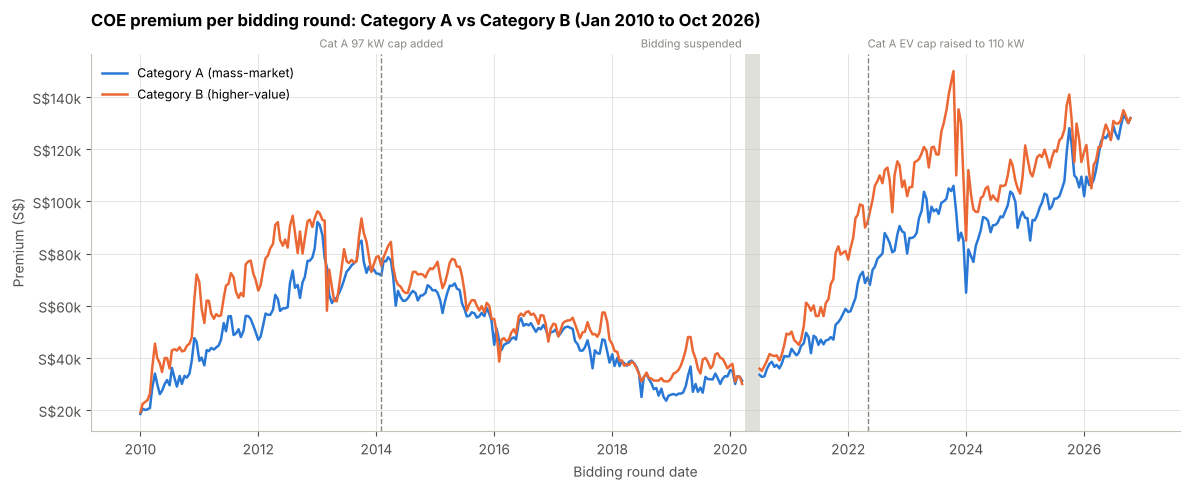

In [45]:
ab_plot = with_gap_breaks(ab)   # lines break at the 2020 suspension instead of joining across it

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ab_plot["round_date"], ab_plot["premium_a"], color=COLOR_A, label="Category A (mass-market)")
ax.plot(ab_plot["round_date"], ab_plot["premium_b"], color=COLOR_B, label="Category B (higher-value)")
mark_policy_changes(ax)

ax.yaxis.set_major_formatter(SGD_THOUSANDS)
ax.set_title("COE premium per bidding round: Category A vs Category B (Jan 2010 to Oct 2026)")
ax.set_xlabel("Bidding round date")
ax.set_ylabel("Premium (S$)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Takeaway:** Cat A and Cat B premiums have moved together since 2010, and by Oct 2026 the two lines sit almost on top of each other at about S$130,000.

Next, the **ratio** (Cat B ÷ Cat A). A ratio of 1.0 means both categories cost the same. The grey line is noisy, so we also draw a rolling average of the last 12 rounds (about 6 months).

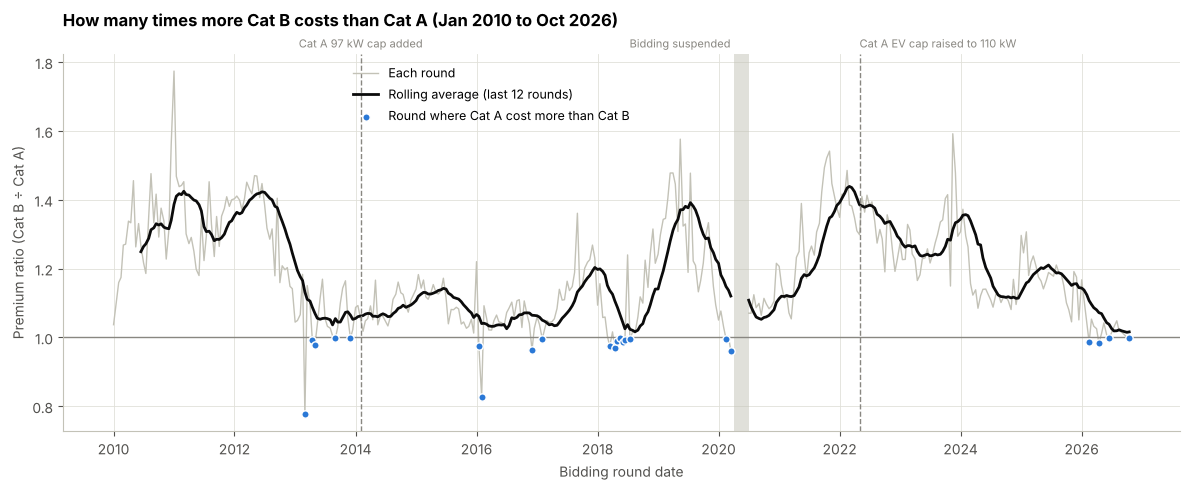

In [46]:
ab["ratio_rolling"] = ab["ratio"].rolling(window=12).mean()   # average of the last 12 rounds
a_wins = ab[ab["a_above_b"]]                                    # rounds where Cat A cost more than Cat B
ab_plot = with_gap_breaks(ab)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ab_plot["round_date"], ab_plot["ratio"], color=LIGHT_GREY, linewidth=1, label="Each round")
ax.plot(ab_plot["round_date"], ab_plot["ratio_rolling"], color=INK, linewidth=2, label="Rolling average (last 12 rounds)")
ax.axhline(1.0, color=GREY, linewidth=1)
ax.scatter(a_wins["round_date"], a_wins["ratio"], color=COLOR_A, s=28, zorder=3,
           edgecolor="white", linewidth=1, label="Round where Cat A cost more than Cat B")
mark_policy_changes(ax)

ax.set_title("How many times more Cat B costs than Cat A (Jan 2010 to Oct 2026)")
ax.set_xlabel("Bidding round date")
ax.set_ylabel("Premium ratio (Cat B ÷ Cat A)")
ax.legend(loc="upper left", bbox_to_anchor=(0.25, 1.0))  # sits over 2014-2018, where the ratio is low
plt.tight_layout()
plt.show()

**Takeaway:** The gap moves in cycles. The rolling ratio fell close to 1.0 in 2013, 2016 and 2018, and widened again each time. The 2026 low (rolling average 1.015) is the lowest on record, but only just below the 2018 low (1.017), so this chart alone cannot tell us whether this time is different.

**Year by year.** One row per year: average premiums, the average gap, how often Cat A cost more, Cat A's share of the A + B quota, and the average bids-to-quota ratio in each category.

In [47]:
yearly = ab.groupby("year").agg(
    rounds=("ratio", "size"),
    avg_premium_a=("premium_a", "mean"),
    avg_premium_b=("premium_b", "mean"),
    avg_gap=("gap", "mean"),
    avg_ratio=("ratio", "mean"),
    lowest_ratio=("ratio", "min"),
    highest_ratio=("ratio", "max"),
    rounds_a_above_b=("a_above_b", "sum"),
    quota_share_a=("quota_share_a", "mean"),
    avg_bids_to_quota_a=("bids_to_quota_a", "mean"),
    avg_bids_to_quota_b=("bids_to_quota_b", "mean"),
)
yearly.round({"avg_premium_a": 0, "avg_premium_b": 0, "avg_gap": 0, "avg_ratio": 3, "lowest_ratio": 3,
              "highest_ratio": 3, "quota_share_a": 3, "avg_bids_to_quota_a": 2, "avg_bids_to_quota_b": 2})

,rounds,avg_premium_a,avg_premium_b,avg_gap,avg_ratio,lowest_ratio,highest_ratio,rounds_a_above_b,quota_share_a,avg_bids_to_quota_a,avg_bids_to_quota_b
year,,,,,,,,,,,
2010,24,30405.0,39834.0,9429.0,1.295,1.037,1.561,0,0.576,1.45,1.49
2011,24,48206.0,64938.0,16731.0,1.354,1.180,1.774,0,0.575,1.63,1.49
2012,24,63898.0,84431.0,20533.0,1.334,1.142,1.470,0,0.597,1.44,1.47
2013,24,74690.0,78712.0,4022.0,1.054,0.778,1.183,5,0.510,2.01,1.87
2014,24,67675.0,73282.0,5606.0,1.084,1.018,1.167,0,0.518,1.74,1.58
2015,24,60601.0,66851.0,6250.0,1.100,1.013,1.183,0,0.599,1.52,1.49
2016,24,49587.0,52122.0,2535.0,1.051,0.828,1.220,3,0.609,1.51,1.66
2017,24,45991.0,51800.0,5810.0,1.133,0.996,1.361,1,0.586,1.35,1.42
2018,24,33038.0,35345.0,2308.0,1.083,0.969,1.315,7,0.552,1.39,1.41


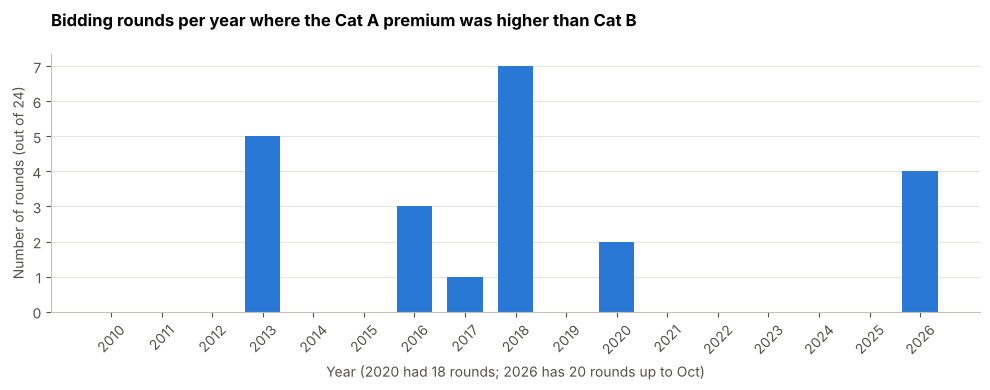

In [48]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(yearly.index, yearly["rounds_a_above_b"], color=COLOR_A, width=0.7)
ax.set_xticks(yearly.index)
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)

ax.set_title("Bidding rounds per year where the Cat A premium was higher than Cat B")
ax.set_xlabel("Year (2020 had 18 rounds; 2026 has 20 rounds up to Oct)")
ax.set_ylabel("Number of rounds (out of 24)")
plt.tight_layout()
plt.show()

**Takeaway:** Cat A costing more than Cat B is not new (22 of 398 rounds, mostly in 2013 and 2018), but 2026 already has 4 such rounds, the most since 2018.

**Has the gap closed like this before, and for how long?** We call a stretch of rounds a *convergence episode* when the 12-round rolling ratio stays below 1.05 (Cat B within 5% of Cat A). For each episode we record how long it lasted, and how wide the rolling ratio got in the 24 rounds (about one year) after it ended.

In [49]:
CONVERGED_BELOW = 1.05

ab["converged"] = ab["ratio_rolling"] < CONVERGED_BELOW
ab["episode_id"] = (ab["converged"] != ab["converged"].shift()).cumsum()  # new id each time converged flips

episodes = ab[ab["converged"]].groupby("episode_id").agg(
    start=("round_date", "min"),
    end=("round_date", "max"),
    rounds=("ratio", "size"),
    lowest_rolling_ratio=("ratio_rolling", "min"),
).reset_index(drop=True)

# How wide did the gap get in the next 24 rounds after each episode ended?
widest_after = []
for end_date in episodes["end"]:
    next_rounds = ab[ab["round_date"] > end_date].head(24)
    widest_after.append(next_rounds["ratio_rolling"].max() if len(next_rounds) > 0 else np.nan)
episodes["widest_rolling_ratio_next_24_rounds"] = widest_after
episodes["status"] = np.where(episodes["end"] == ab["round_date"].max(), "ongoing", "ended")

episodes.round({"lowest_rolling_ratio": 3, "widest_rolling_ratio_next_24_rounds": 3})

,start,end,rounds,lowest_rolling_ratio,widest_rolling_ratio_next_24_rounds,status
0,2013-08-15,2013-08-15,1,1.037,1.075,ended
1,2013-09-15,2013-10-01,2,1.045,1.088,ended
2,2016-02-01,2016-07-15,12,1.025,1.080,ended
3,2017-02-15,2017-05-15,7,1.034,1.204,ended
4,2018-06-01,2018-10-01,9,1.017,1.392,ended
5,2026-06-01,2026-10-15,10,1.015,NaN,ongoing


**Takeaway:** Every past convergence episode ended within 12 rounds (about 6 months), and the gap opened up again within a year. After 2013 and 2016 it only re-opened a little (rolling ratio about 1.08) before closing again; after 2017 and 2018 it re-opened much more (1.20 and 1.39). The 2026 episode has lasted 10 rounds so far and is still going: it is the deepest on record, but not yet the longest. If it passes 12 rounds, that would be the first sign that this convergence is lasting rather than another cycle.

Summary table: compare the gap across the three policy periods.

In [50]:
period_summary = ab.groupby("policy_period").agg(
    rounds=("ratio", "count"),
    avg_premium_a=("premium_a", "mean"),
    avg_premium_b=("premium_b", "mean"),
    avg_gap=("gap", "mean"),
    avg_ratio=("ratio", "mean"),
    rounds_a_above_b=("a_above_b", "sum"),
)
period_summary["pct_rounds_a_above_b"] = period_summary["rounds_a_above_b"] / period_summary["rounds"] * 100

period_summary.round(2)

,rounds,avg_premium_a,avg_premium_b,avg_gap,avg_ratio,rounds_a_above_b,pct_rounds_a_above_b
policy_period,,,,,,,
1. Jan 2010 - Jan 2014 (engine size only),98,54667.71,67220.77,12553.05,1.26,5,5.10
2. Feb 2014 - Apr 2022 (97 kW cap),192,47057.12,53943.53,6886.40,1.15,13,6.77
3. May 2022 onwards (110 kW cap for EVs),108,98404.51,115721.61,17317.10,1.19,4,3.70


**Takeaway:** Averages over a whole policy period hide the trend. Since May 2022 the average ratio is 1.19, wider than 2014 to 2022, because 2022 and 2023 had very large gaps, even though 2026 is almost level. Look at the trend within a period, not only its average.

### 4.2 Supply and competition: quota and bids-to-quota

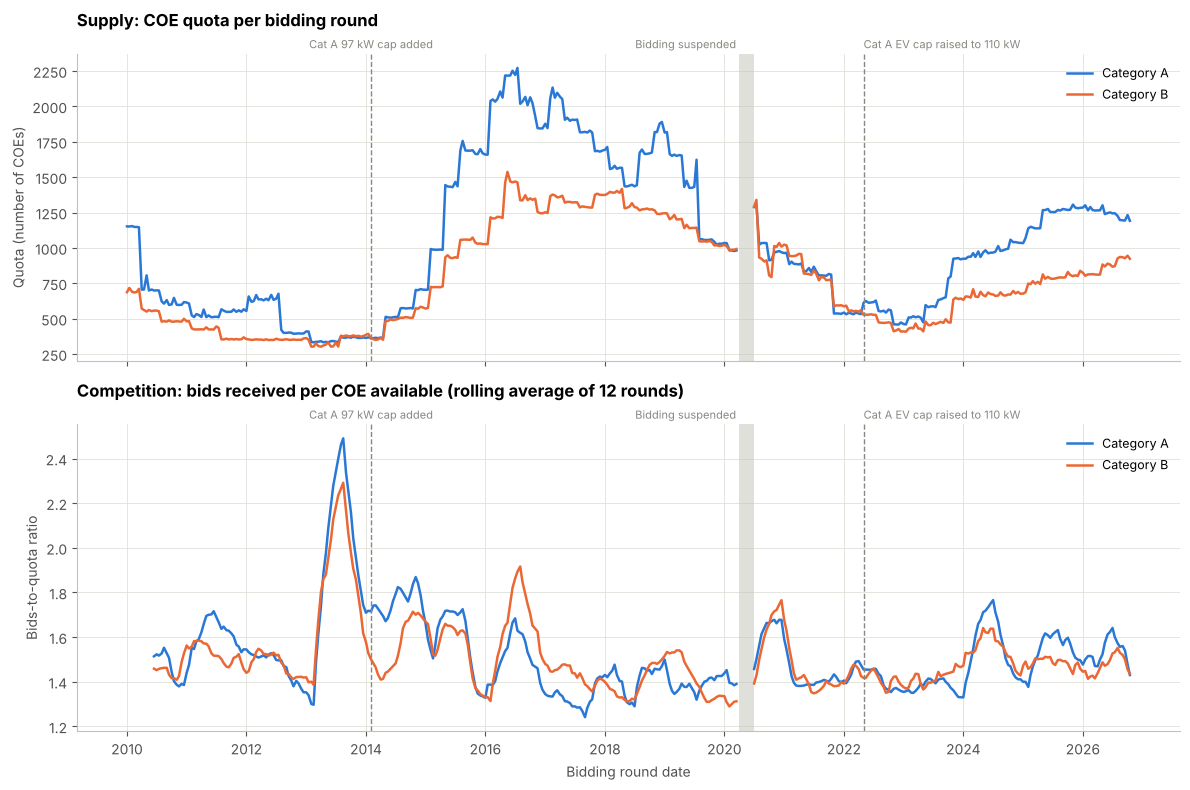

In [51]:
ab["bids_to_quota_a_rolling"] = ab["bids_to_quota_a"].rolling(window=12).mean()
ab["bids_to_quota_b_rolling"] = ab["bids_to_quota_b"].rolling(window=12).mean()
ab_plot = with_gap_breaks(ab)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Top chart: supply (how many COEs were available)
ax1.plot(ab_plot["round_date"], ab_plot["quota_a"], color=COLOR_A, label="Category A")
ax1.plot(ab_plot["round_date"], ab_plot["quota_b"], color=COLOR_B, label="Category B")
mark_policy_changes(ax1)
ax1.set_title("Supply: COE quota per bidding round")
ax1.set_ylabel("Quota (number of COEs)")
ax1.legend(loc="upper right")

# Bottom chart: competition (bids per COE), smoothed over 12 rounds
ax2.plot(ab_plot["round_date"], ab_plot["bids_to_quota_a_rolling"], color=COLOR_A, label="Category A")
ax2.plot(ab_plot["round_date"], ab_plot["bids_to_quota_b_rolling"], color=COLOR_B, label="Category B")
mark_policy_changes(ax2)
ax2.set_title("Competition: bids received per COE available (rolling average of 12 rounds)")
ax2.set_xlabel("Bidding round date")
ax2.set_ylabel("Bids-to-quota ratio")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

**Takeaway:** Since 2023, Cat A has received clearly more quota than Cat B (about 60% of the combined A + B quota in 2024 to 2026, see the yearly table), yet since 2024 its average bids-to-quota ratio has been higher than Cat B's. Cat A got more crowded even with more supply, which suggests demand for Cat A grew faster than its extra quota.

**Does relative competition explain the gap?** If Cat B gets more bids per COE than Cat A, we would expect Cat B's premium to rise relative to Cat A's. We measure `competition_ratio` = Cat B bids-to-quota ÷ Cat A bids-to-quota, and correlate it with the premium ratio in two ways:
- **levels:** does a high competition ratio go with a high premium ratio?
- **round-to-round changes:** when the competition ratio rises from one round to the next, does the premium ratio rise too? This removes slow trends that can make two series look linked.

This uses bids received, so it **explains** premiums after the fact; it cannot forecast them.

In [52]:
ab["competition_ratio"] = ab["bids_to_quota_b"] / ab["bids_to_quota_a"]


def competition_link(rounds):
    return pd.Series({
        "rounds": len(rounds),
        "corr_levels": rounds["ratio"].corr(rounds["competition_ratio"]),
        "corr_round_to_round_changes": rounds["ratio"].diff().corr(rounds["competition_ratio"].diff()),
    })


competition_table = ab.groupby("policy_period").apply(competition_link)
competition_table.loc["All rounds"] = competition_link(ab)
competition_table.round(2)

,rounds,corr_levels,corr_round_to_round_changes
policy_period,,,
1. Jan 2010 - Jan 2014 (engine size only),98.0,0.11,0.07
2. Feb 2014 - Apr 2022 (97 kW cap),192.0,0.08,0.57
3. May 2022 onwards (110 kW cap for EVs),108.0,0.32,0.48
All rounds,398.0,0.11,0.37


**Takeaway:** In levels the link is weak (about 0.1), but round to round it is clearer since 2014 (0.57 for Feb 2014 to Apr 2022, and 0.48 since May 2022): when Cat B gets relatively more crowded, Cat B's premium rises relative to Cat A's in that same round. Bidding pressure explains part of the short-term swings in the gap, not its long-run level.

### 4.3 Category E: what happens when all car buyers bid in one pool?

Category E is the "open" category: a Cat E COE can be used for any car (and also for goods vehicles and buses). So it is the closest thing in the data to a single pool where mass-market and higher-value buyers compete. For each year we compare Cat E's premium with Cat A's and Cat B's.

In [53]:
ab["e_minus_b"] = ab["premium_e"] - ab["premium_b"]
ab["e_minus_a"] = ab["premium_e"] - ab["premium_a"]
ab["e_at_or_above_both"] = ab["premium_e"] >= ab[["premium_a", "premium_b"]].max(axis=1)

cat_e_yearly = ab.groupby("year").agg(
    median_e_minus_a=("e_minus_a", "median"),
    median_e_minus_b=("e_minus_b", "median"),
    share_rounds_e_at_or_above_a_and_b=("e_at_or_above_both", "mean"),
)
cat_e_yearly.round({"median_e_minus_a": 0, "median_e_minus_b": 0, "share_rounds_e_at_or_above_a_and_b": 2})

,median_e_minus_a,median_e_minus_b,share_rounds_e_at_or_above_a_and_b
year,,,
2010,11234.0,1000.0,0.83
2011,17594.0,793.0,0.71
2012,21262.0,998.0,0.62
2013,3950.0,881.0,0.62
2014,5755.0,114.0,0.58
2015,8245.0,974.0,0.79
2016,2686.0,167.0,0.46
2017,5742.0,106.0,0.58
2018,1316.0,346.0,0.54


**Takeaway:** Cat E's premium sits **at or just above Cat B**: in every year the median Cat E premium is within S$3,000 of Cat B's, and Cat E is at or above both A and B in 46% to 96% of rounds. In the open pool, the price is set near the level that higher-value buyers are willing to pay.

**What this suggests (reasoning, not yet tested):** Cat E is not a direct model of a merged A + B category. Its quota is small, and Cat B buyers can switch into it. But simple auction logic gives a useful bound: if everyone kept bidding as they do today and the A and B quotas were simply added together, the merged clearing premium must land **between** the Cat A and Cat B premiums. (At the Cat A price, Cat B bidders would want more COEs than their old quota, so the price must rise. At the Cat B price, Cat A bidders would want fewer than their old quota, so it must fall.) So the size of the A-B gap is the most a merger could raise Cat A buyers' premium, if bidding behaviour stayed the same. We test where in that band the price might land in Section 5.

### 4.4 New car registrations: what is the market buying?

First, a sanity check that also shows the overall market: new cars registered each month, next to the number of A, B and E COEs won.

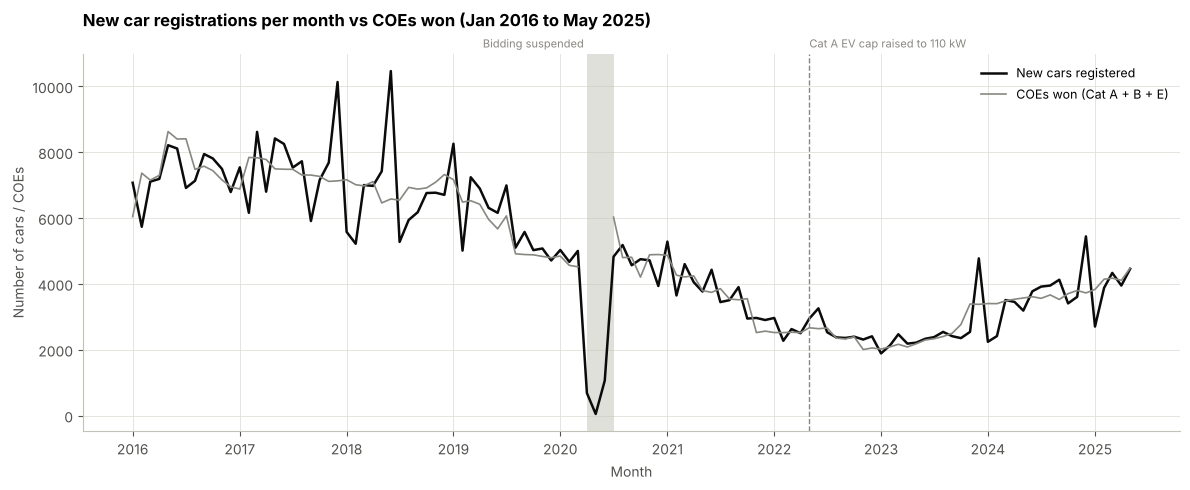

In [54]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(reg_monthly["month"], reg_monthly["total_cars"], color=INK, label="New cars registered")
ax.plot(coes_won_monthly.index, coes_won_monthly.values, color=GREY, linewidth=1.2, label="COEs won (Cat A + B + E)")
mark_policy_changes(ax, show_2014=False)

ax.set_title("New car registrations per month vs COEs won (Jan 2016 to May 2025)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of cars / COEs")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

**Takeaway:** New car registrations closely follow the number of COEs won, because every new car needs a COE. They fell from about 7,300 a month in 2016 to about 2,500 a month in 2022 and 2023, then recovered to about 3,900 a month in early 2025. Registrations are spikier than COEs won (e.g. Dec 2017, Jun 2018, Dec 2023), because buyers can bunch registrations into particular months.

**Fuel mix by year**, using the consistent fuel groups from Step 8 of cleaning.

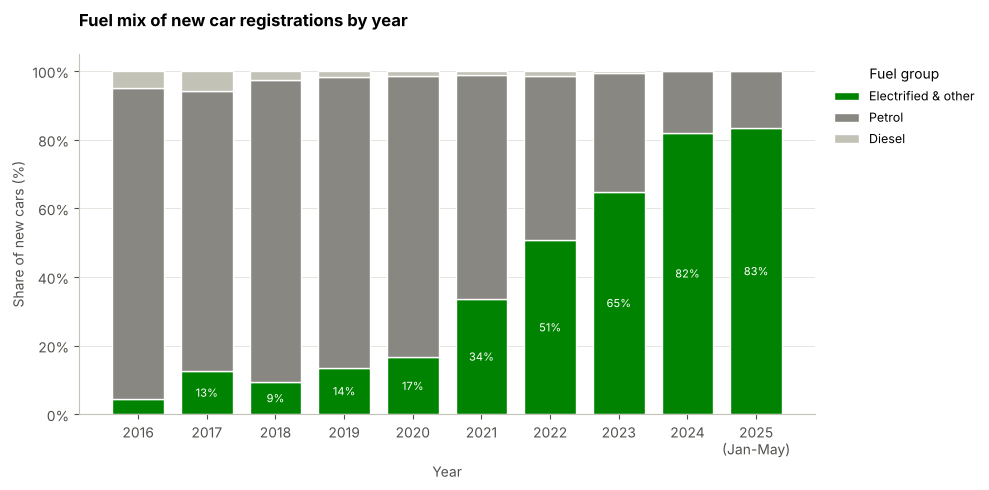

In [55]:
registrations["year"] = registrations["month"].dt.year

fuel_by_year = registrations.groupby(["year", "fuel_group"])["number"].sum().unstack()
# Turn counts into percentages: divide each row by that year's total
fuel_share_by_year = fuel_by_year.div(fuel_by_year.sum(axis=1), axis=0) * 100

fuel_order = ["Electrified & other", "Petrol", "Diesel"]
fuel_colors = {"Electrified & other": COLOR_EV, "Petrol": GREY, "Diesel": LIGHT_GREY}

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(fuel_share_by_year))
for fuel in fuel_order:
    values = fuel_share_by_year[fuel].values
    ax.bar(fuel_share_by_year.index, values, bottom=bottom, color=fuel_colors[fuel],
           width=0.75, edgecolor="white", linewidth=1, label=fuel)
    bottom += values
# Label only the electrified share, where it fits inside the bar
for year, share in fuel_share_by_year["Electrified & other"].items():
    if share >= 8:
        ax.text(year, share / 2, f"{share:.0f}%", ha="center", va="center", fontsize=8, color="white")

ax.set_xticks(fuel_share_by_year.index)
ax.set_xticklabels([str(y) if y < 2025 else "2025\n(Jan-May)" for y in fuel_share_by_year.index])
ax.yaxis.set_major_formatter(PERCENT)
ax.grid(axis="x", visible=False)
ax.set_title("Fuel mix of new car registrations by year")
ax.set_xlabel("Year")
ax.set_ylabel("Share of new cars (%)")
ax.legend(title="Fuel group", loc="upper left", bbox_to_anchor=(1.01, 1))  # legend outside the chart
plt.tight_layout()
plt.show()

**Takeaway:** Petrol cars fell from 90% of new cars in 2016 to about 17% in 2025, and diesel almost disappeared. Electrified cars (fully electric plus hybrids) now make up over 80% of new cars.

"Electrified" mixes two very different things: **fully electric** cars (which can be tuned to fit Cat A's 110 kW cap) and **hybrids** (which still have a petrol engine, so the 1,600cc and 97 kW rules apply). From July 2022 we can split them, quarter by quarter.

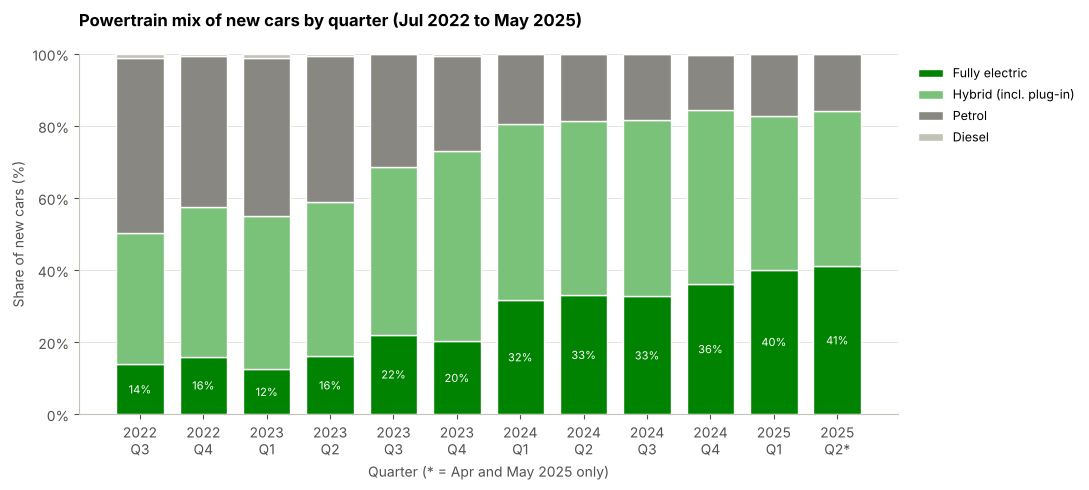

In [56]:
since_jul_2022 = registrations[registrations["month"] >= "2022-07-01"]
quarter = since_jul_2022["month"].dt.to_period("Q")
powertrain_by_quarter = since_jul_2022.groupby([quarter, "powertrain"])["number"].sum().unstack(fill_value=0)
powertrain_share = powertrain_by_quarter.div(powertrain_by_quarter.sum(axis=1), axis=0) * 100

powertrain_order = ["Fully electric", "Hybrid", "Petrol", "Diesel"]
powertrain_colors = {"Fully electric": COLOR_EV, "Hybrid": COLOR_HYBRID, "Petrol": GREY, "Diesel": LIGHT_GREY}
quarter_labels = [f"{q.year}\nQ{q.quarter}" for q in powertrain_share.index]
quarter_labels[-1] += "*"   # the last quarter only has Apr and May 2025
x = np.arange(len(powertrain_share))

fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(powertrain_share))
for powertrain in powertrain_order:
    values = powertrain_share[powertrain].values
    ax.bar(x, values, bottom=bottom, color=powertrain_colors[powertrain], width=0.75, edgecolor="white",
           linewidth=1, label="Hybrid (incl. plug-in)" if powertrain == "Hybrid" else powertrain)
    bottom += values
for i, share in enumerate(powertrain_share["Fully electric"]):
    ax.text(i, share / 2, f"{share:.0f}%", ha="center", va="center", fontsize=8, color="white")

ax.set_xticks(x)
ax.set_xticklabels(quarter_labels)
ax.yaxis.set_major_formatter(PERCENT)
ax.grid(axis="x", visible=False)
ax.set_title("Powertrain mix of new cars by quarter (Jul 2022 to May 2025)")
ax.set_xlabel("Quarter (* = Apr and May 2025 only)")
ax.set_ylabel("Share of new cars (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Takeaway:** Fully electric cars rose from 14% of new cars in Q3 2022 to 41% in Q2 2025, taking share mostly from petrol (down from 48% to 16%). Hybrids stayed between about 37% and 53%, so most of the recent growth in "electrified" cars is fully electric cars.

Which brands are gaining or losing share? We follow the 6 biggest brands of 2024, highlighting BYD.

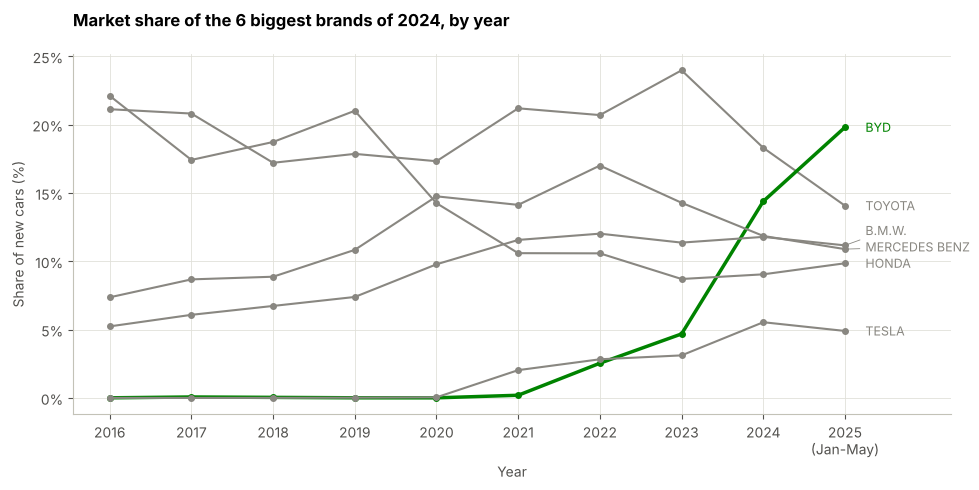

In [57]:
brand_by_year = registrations.groupby(["year", "make"])["number"].sum().unstack(fill_value=0)
brand_share_by_year = brand_by_year.div(brand_by_year.sum(axis=1), axis=0) * 100

top6_brands_2024 = brand_by_year.loc[2024].sort_values(ascending=False).head(6).index
brand_colors = {brand: (COLOR_EV if brand == "BYD" else GREY) for brand in top6_brands_2024}

fig, ax = plt.subplots(figsize=(10, 5))
for brand in top6_brands_2024:
    ax.plot(brand_share_by_year.index, brand_share_by_year[brand], color=brand_colors[brand],
            linewidth=2.5 if brand == "BYD" else 1.5, marker="o", markersize=4)
last_year = brand_share_by_year.index.max()
label_line_ends(ax, last_year, brand_share_by_year.loc[last_year, top6_brands_2024].to_dict(),
                brand_colors, min_gap=1.2, offset=0.25)

ax.set_xticks(brand_share_by_year.index)
ax.set_xticklabels([str(y) if y < 2025 else "2025\n(Jan-May)" for y in brand_share_by_year.index])
ax.set_xlim(right=last_year + 1.3)  # room for the labels
ax.yaxis.set_major_formatter(PERCENT)
ax.set_title("Market share of the 6 biggest brands of 2024, by year")
ax.set_xlabel("Year")
ax.set_ylabel("Share of new cars (%)")
plt.tight_layout()
plt.show()

**Takeaway:** BYD went from almost zero before 2022 to the biggest brand in early 2025 (about 20% of new cars), while Toyota and Mercedes-Benz lost share. Most of BYD's growth came after 2023.

**Who sells the fully electric cars?** Total fully electric registrations by brand, July 2022 to May 2025 (the only period where EVs are recorded separately).

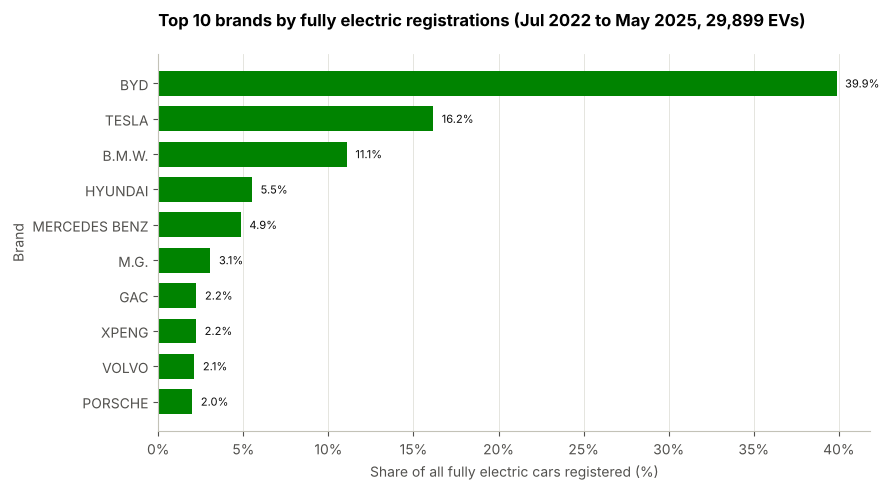

BYD + Tesla share of EVs: 56.0%
Premium brands' share of EVs: 19.0%


In [58]:
ev_by_brand = since_jul_2022[since_jul_2022["powertrain"] == "Fully electric"].groupby("make")["number"].sum()
ev_brand_share = (ev_by_brand / ev_by_brand.sum() * 100).sort_values(ascending=False)
top10_ev = ev_brand_share.head(10).sort_values()  # smallest first, so the biggest bar is at the top

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10_ev.index, top10_ev.values, color=COLOR_EV, height=0.7)
for brand, share in top10_ev.items():
    ax.text(share + 0.5, brand, f"{share:.1f}%", va="center", fontsize=8, color=INK)

ax.xaxis.set_major_formatter(PERCENT)
ax.grid(axis="y", visible=False)
ax.set_title(f"Top 10 brands by fully electric registrations (Jul 2022 to May 2025, {ev_by_brand.sum():,} EVs)")
ax.set_xlabel("Share of all fully electric cars registered (%)")
ax.set_ylabel("Brand")
plt.tight_layout()
plt.show()

print(f"BYD + Tesla share of EVs: {ev_brand_share[['BYD', 'TESLA']].sum():.1f}%")
print(f"Premium brands' share of EVs: {ev_brand_share[ev_brand_share.index.isin(premium_brands)].sum():.1f}%")

**Takeaway:** The EV market is concentrated. BYD alone sold about 40% of all fully electric cars since July 2022, and BYD and Tesla together sold over half. About one in five EVs came from premium brands (mainly BMW).

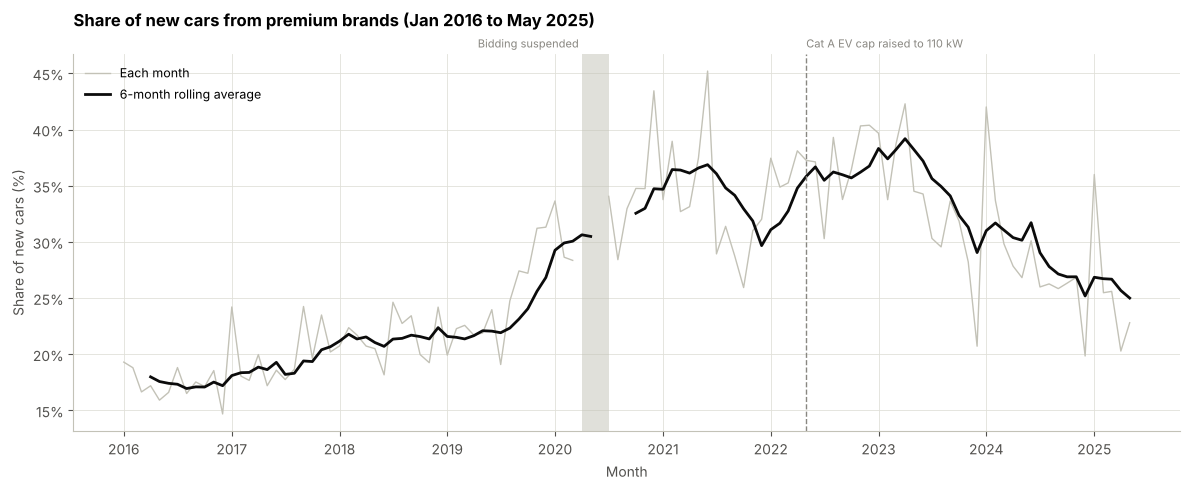

In [59]:
premium_share_rolling = reg_monthly["premium_brand_share"].rolling(window=6, min_periods=4).mean()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(reg_monthly["month"], reg_monthly["premium_brand_share"] * 100, color=LIGHT_GREY, linewidth=1, label="Each month")
ax.plot(reg_monthly["month"], premium_share_rolling * 100, color=INK, linewidth=2, label="6-month rolling average")
mark_policy_changes(ax, show_2014=False)

ax.yaxis.set_major_formatter(PERCENT)
ax.set_title("Share of new cars from premium brands (Jan 2016 to May 2025)")
ax.set_xlabel("Month")
ax.set_ylabel("Share of new cars (%)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Takeaway:** Premium-brand share more than doubled, from about 17% in 2016 to a peak of about 39% (6-month average) in early 2023, then fell back to about 25% by 2025, in the same period that the EV share took off.

### 4.5 Linking registrations to the premium gap (joined data)

How does the premium ratio move with each registration feature? A correlation near +1 or -1 means they move closely together; near 0 means little link. **Correlation is not causation:** two things that both trend over time can look linked even if one does not cause the other. So, as in 4.2, we also correlate **month-to-month changes**, which removes slow trends. We only use changes between back-to-back months, so the jump across the Apr to Jun 2020 gap is left out.

In [60]:
compare_cols = ["bids_to_quota_a", "bids_to_quota_b", "total_cars", "electrified_share", "premium_brand_share"]

back_to_back = merged["month"].diff() <= pd.Timedelta(days=31)   # previous row is the previous month
monthly_changes = merged[compare_cols + ["ratio"]].diff()[back_to_back]

correlation_table = pd.DataFrame({
    "corr_levels": merged[compare_cols].corrwith(merged["ratio"]),
    "corr_monthly_changes": monthly_changes[compare_cols].corrwith(monthly_changes["ratio"]),
})
correlation_table.round(2).sort_values("corr_levels")

,corr_levels,corr_monthly_changes
total_cars,-0.49,-0.03
bids_to_quota_b,-0.16,0.11
bids_to_quota_a,-0.11,-0.03
electrified_share,0.36,-0.00
premium_brand_share,0.41,0.05


**Takeaway:** In levels, the ratio looks linked to premium-brand share (+0.41), electrified share (+0.36) and total registrations (-0.49). But month to month, none of these links is bigger than 0.05 in size. So the level correlations come from slow trends that happen to overlap, not from the features moving together. (At the monthly level, even bidding pressure only reaches 0.11; the round-level link in 4.2 is stronger.) Treat these as clues to test in Section 5, not proof.

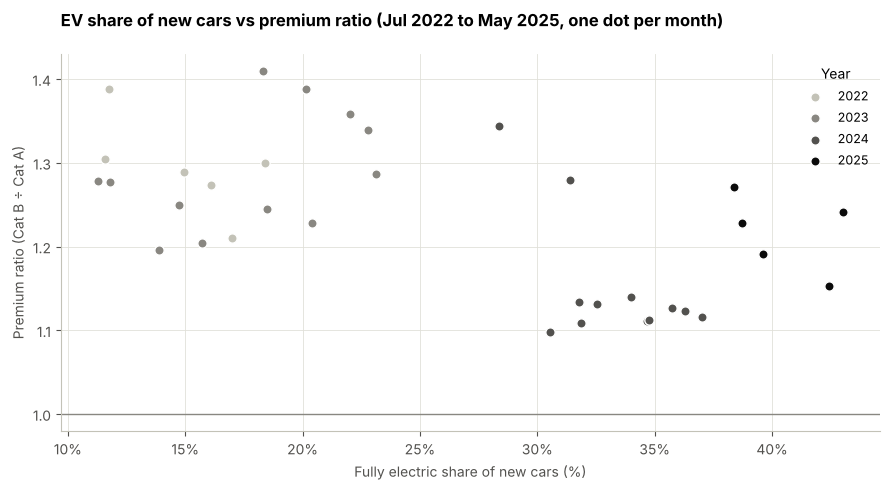

Correlation between EV share and premium ratio (levels): -0.58
Correlation of month-to-month changes: -0.25
Number of months: 35


In [61]:
# Only the months where fully electric cars were recorded separately (Jul 2022 onwards)
ev_months = merged.dropna(subset=["ev_share"])
year_shades = {2022: "#c3c2b7", 2023: "#898781", 2024: "#52514e", 2025: "#0b0b0b"}  # light to dark = earlier to later

fig, ax = plt.subplots(figsize=(9, 5))
# Draw each year in its own shade so we can see how the pattern changes over time
for year, group in ev_months.groupby(ev_months["month"].dt.year):
    ax.scatter(group["ev_share"] * 100, group["ratio"], s=45, color=year_shades[year],
               edgecolor="white", linewidth=1, label=str(year))
ax.axhline(1.0, color=GREY, linewidth=1)

ax.xaxis.set_major_formatter(PERCENT)
ax.set_title("EV share of new cars vs premium ratio (Jul 2022 to May 2025, one dot per month)")
ax.set_xlabel("Fully electric share of new cars (%)")
ax.set_ylabel("Premium ratio (Cat B ÷ Cat A)")
ax.legend(title="Year", loc="upper right")
plt.tight_layout()
plt.show()

ev_changes = ev_months[["ev_share", "ratio"]].diff()
print("Correlation between EV share and premium ratio (levels):", round(ev_months["ev_share"].corr(ev_months["ratio"]), 2))
print("Correlation of month-to-month changes:", round(ev_changes["ev_share"].corr(ev_changes["ratio"]), 2))
print("Number of months:", len(ev_months))

**Takeaway:** From July 2022 to May 2025, months with a higher EV share tended to have a smaller A-B gap (correlation -0.58 over 35 months). But the month-to-month link is much weaker (-0.25), and in 2025 the ratio went back up while EV share kept rising. So EV share alone does not explain the gap. This is a lead, not proof.

### 4.6 EDA summary

**What the data shows:**
1. **The A-B gap is cyclical, and 2026 is at the bottom of a cycle.** The 12-round rolling ratio fell close to 1.0 in 2013, 2016 and 2018, and every time the gap opened up again within a year (to a rolling ratio of 1.08 to 1.39). The 2026 low (1.015) is the deepest on record but only just below 2018 (1.017). The 2026 episode is 10 rounds long so far, still shorter than 2016's 12.
2. **Cat A has caught up despite getting more supply.** Since 2023 Cat A has had about 56% to 61% of the combined quota, yet since 2024 its average bids-to-quota ratio has been higher than Cat B's. Round to round, changes in relative bidding pressure explain part of the swings in the gap (correlation 0.57 for 2014 to 2022, 0.48 since May 2022).
3. **The open category (Cat E) prices near Cat B.** When all buyers compete in one pool, the premium sits at or just above the higher-value category's level.
4. **The car market has changed a lot.** Fully electric cars went from 14% to 41% of new cars (Q3 2022 to Q2 2025), taking share mostly from petrol. BYD went from almost zero to the top brand, and BYD and Tesla sell over half of all EVs. Premium-brand share has fallen since 2023.
5. **Registration trends and the gap move together over years, but much less month to month.** Correlations in levels shrink sharply in monthly changes (EV share -0.58 to -0.25; premium-brand share, electrified share and total registrations to near zero).

**Important limits:**
- Registration data ends in May 2025, so it cannot directly explain the 2026 convergence.
- The registration data does not record which COE category each car used, so we cannot directly count EVs bidding in Cat A.

**Questions to take into Section 5:**
- Can past premiums and quotas forecast the next round better than the "last round" and rolling-average baselines? (Bids received cannot be used to forecast.)
- If the 2026 convergence follows past cycles, when would the gap re-open? What would make this time different?
- Under a merged category, where in the band between Cat A and Cat B would the premium land, and how much would Cat A buyers pay compared with today? (Test quota-weighted average, and positions closer to Cat B, as Cat E suggests.)

## 5. Analysis & Modelling

*Instructions:* Explain your method and why you chose it. If you build a model:
- Use **time-based validation** (train on earlier data, test on later data). Do not use random splits.
- Compare against **simple baselines**, such as the previous round's premium or a rolling average.
- **Bids received** is only known after a round closes. Use it to explain premiums, not to forecast them.
- A merged Category A/B premium cannot be observed. If you model one, state your assumption and test how sensitive your results are to it.

A model is not required. A well-reasoned statistical or descriptive analysis is fine.

In [62]:
# Your analysis here

## 6. Visualisations

*Instructions:* Generate every chart used in your deck here. Each chart should have a clear title, labelled axes with units, and a one-line takeaway in a markdown cell below it.

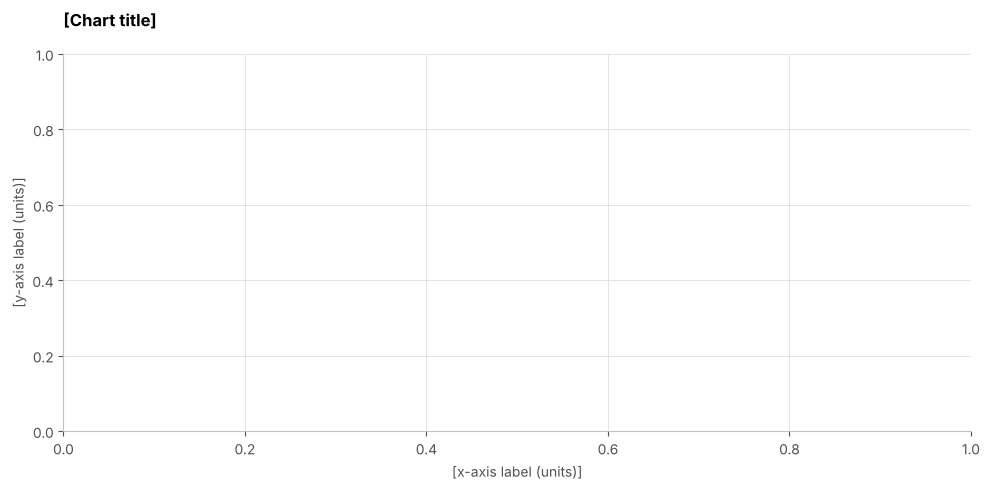

In [63]:
# Chart 1: [title]
fig, ax = plt.subplots()
# ax.plot(...)
ax.set_title("[Chart title]")
ax.set_xlabel("[x-axis label (units)]")
ax.set_ylabel("[y-axis label (units)]")
plt.tight_layout()
plt.show()

**Takeaway:** [One sentence on what this chart shows]

## 7. Key Findings & Recommendation

*Instructions:* Summarise your main findings and state your recommendation. This should match your deck.

**Recommendation:** [Your recommendation in one or two sentences]

**Key findings:**
1. [Finding 1]
2. [Finding 2]
3. [Finding 3]

## 8. Assumptions & Limitations

**What the data shows:**
- [Supported directly by the data. See the EDA summary in 4.6 for candidates.]

**What we assumed:**
- **A blank registration `number` means 0 cars.** Zeros stop exactly when blanks start (Jul 2018), no month has both, and yearly registrations stay within 0.97 to 1.06 of COEs won in every full year, before and after the switch. Low sensitivity.
- **Feb 2010 round 1 Cat B quota is 690, not 1,154.** Set equal to successful bids, because the original value contradicts the row's own bid counts. Only changes that round's bids-to-quota; outside the joined window.
- **Jan 2010 round 2 Cat D premium removed** (a copy of Cat C's value). Cat D is not used in the A/B analysis, so no effect.
- **Monthly COE values:** premiums are the simple average of the two rounds; quotas and bids are summed.
- **Registrations are matched to COE results of the same month.** Same-month correlation is highest (0.92), but a COE can be used a month or more later.
- **"Premium brand" list is our own judgement** and is only a stand-in for "higher-value car". It is not the same as Cat B.
- **Round 2 is plotted on the 15th** of each month; this is for plotting only.
- [Add modelling assumptions from Section 5, e.g. how the merged premium is defined]

**What is speculation:**
- [Interpretation not directly supported by the data]

**Limitations:**
- The registration data does not record the COE category of each car, so links between EV growth and Cat A demand are indirect.
- Fully electric and hybrid cars cannot be told apart before Jul 2022 (both are in `Others`), so EV trends cover under 3 years.
- Registration data ends in May 2025, while COE data runs to Oct 2026; the 2026 convergence cannot be linked to registration trends.
- Apr to Jun 2020 has no bidding, and registration shares for those months are blanked out (only 48 to 1,064 cars a month).
- `importer_type` (authorised dealer vs parallel importer) only exists from 2023.

## 9. Data Sources & Declarations

**Data sources:**
| Dataset | Source (link) | Date downloaded |
| --- | --- | --- |
| COE bidding results | Land Transport Authority, *COE Bidding Results / Prices*, via data.gov.sg (provided by SDS) | – |
| Vehicle registrations | Land Transport Authority, *New Registration of Cars by Make*, via data.gov.sg (provided by SDS) | – |
| [Additional dataset, if any] | [Link] | [DD MMM YYYY] |

**Policy references (not datasets):**
- LTA circular VRL 04/2022, revised Cat A power threshold for fully electric cars (97 kW to 110 kW from the May 2022 first bidding exercise): https://onemotoring.lta.gov.sg/content/dam/onemotoring/pdf/Circulars%20to%20ESAs/2022/VRL_04_2022.pdf

**AI tool use:** [State whether and how you used AI tools, e.g. "Used ChatGPT for debugging plotting code."]